# Train — ResNet-18 (scratch)

Trains and evaluates ResNet-18 (scratch) from random initial weights (no ImageNet pretraining), with the untuned `SCRATCH_HYPERPARAMS`, then saves its results and weights for the results notebooks.

In [1]:
from wwtw_utils import *

Using device: cuda
Test set ID: Atlantis
Train-time augmentation: on
Classes found (3): ['Dysfunctional', 'Functional', 'Suboptimal']


## Data loaders and class weights

In [2]:
cfg = SCRATCH_HYPERPARAMS

# Batch sizes above MICRO_BATCH_CAP are reached with gradient accumulation.
micro_batch = min(cfg["batch_size"], MICRO_BATCH_CAP)
accum_steps = max(1, round(cfg["batch_size"] / micro_batch))
print(f"ResNet-18 (scratch): micro batch = {micro_batch}, accumulation steps = {accum_steps} "
      f"(effective batch size ≈ {micro_batch * accum_steps}, target = {cfg['batch_size']})")

train_ds_arch, val_ds_arch, test_ds_arch, train_loader_arch, val_loader_arch, test_loader_arch = \
    get_dataloaders(cfg["img_size"], micro_batch)

class_weights_arch = make_class_weights(train_ds_arch)

ResNet-18 (scratch): micro batch = 16, accumulation steps = 2 (effective batch size ≈ 32, target = 32)
Train: 1310 | Val: 320 | Test: 113


## Model

In [3]:
model = models.resnet18(weights=None)
in_f = model.fc.in_features
model.fc = build_classifier_head(in_f, cfg["hidden_layers"], cfg["neurons"], num_classes)

model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights_arch)
optimizer = optim.Adam(
    model.parameters(),
    lr=cfg["lr"],
    betas=(cfg["beta1"], ADAM_BETA2),
    weight_decay=WEIGHT_DECAY,
)
scheduler = StepLR(optimizer, step_size=cfg["step_size"], gamma=0.1)

## Train

[ResNet-18 (scratch)] Gradient accumulation: 2 micro-batches per optimizer step.


[ResNet-18 (scratch)] Epoch   1/100 | LR: 1.00e-04 | train loss 1.0658 acc 0.509 | val loss 0.8920 acc 0.681 *


[ResNet-18 (scratch)] Epoch   2/100 | LR: 1.00e-04 | train loss 0.9618 acc 0.599 | val loss 0.8237 acc 0.662 *


[ResNet-18 (scratch)] Epoch   3/100 | LR: 1.00e-04 | train loss 0.9087 acc 0.619 | val loss 0.7720 acc 0.653 *


[ResNet-18 (scratch)] Epoch   4/100 | LR: 1.00e-04 | train loss 0.9001 acc 0.590 | val loss 0.8384 acc 0.600


...

[ResNet-18 (scratch)] Epoch  45/100 | LR: 1.00e-07 | train loss 0.6119 acc 0.736 | val loss 0.5650 acc 0.759


[ResNet-18 (scratch)] Epoch  46/100 | LR: 1.00e-07 | train loss 0.6098 acc 0.723 | val loss 0.5650 acc 0.769


[ResNet-18 (scratch)] Epoch  47/100 | LR: 1.00e-07 | train loss 0.6221 acc 0.730 | val loss 0.5634 acc 0.756


[ResNet-18 (scratch)] Epoch  48/100 | LR: 1.00e-07 | train loss 0.6070 acc 0.747 | val loss 0.5640 acc 0.762


[ResNet-18 (scratch)] Epoch  49/100 | LR: 1.00e-07 | train loss 0.6157 acc 0.726 | val loss 0.5658 acc 0.753

[ResNet-18 (scratch)] No val loss improvement for 10 epochs, stopping at epoch 49.

[ResNet-18 (scratch)] Restored best checkpoint (val loss = 0.5599)


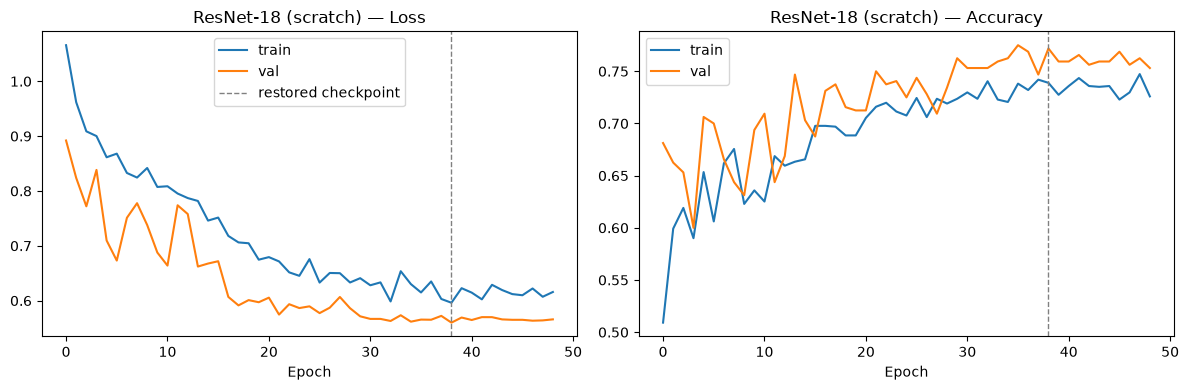

In [4]:
history = train_model(
    model, train_loader_arch, val_loader_arch, optimizer, scheduler,
    criterion, EPOCHS, EARLY_STOP_PATIENCE, "ResNet-18 (scratch)", is_inception=False,
    accum_steps=accum_steps,
)
plot_training_curves(history, "ResNet-18 (scratch)")

## Evaluate on the test set

[ResNet-18 (scratch)] Test accuracy: 0.469


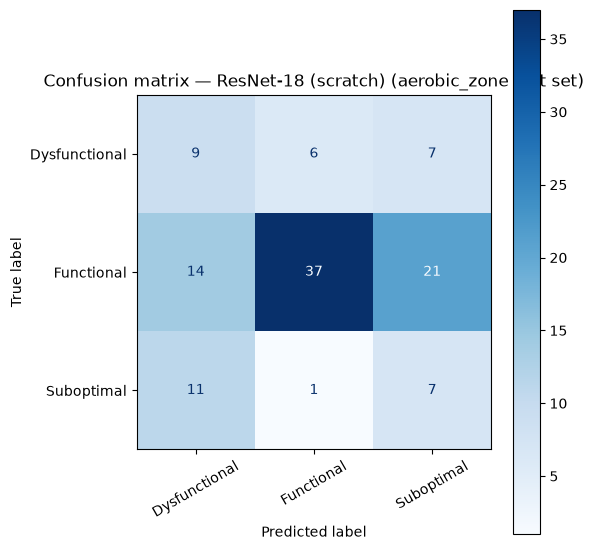

               precision    recall  f1-score   support

Dysfunctional      0.265     0.409     0.321        22
   Functional      0.841     0.514     0.638        72
   Suboptimal      0.200     0.368     0.259        19

     accuracy                          0.469       113
    macro avg      0.435     0.430     0.406       113
 weighted avg      0.621     0.469     0.513       113



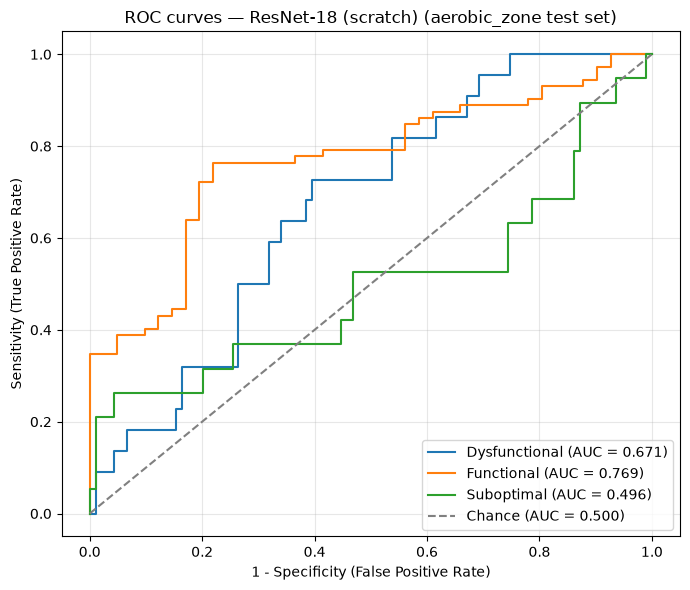

AUC (area under ROC curve) per class:
  Dysfunctional  : 0.671
  Functional     : 0.769
  Suboptimal     : 0.496

Mean AUC (over 3/3 classes with test examples): 0.645


(np.float64(0.4690265486725664),
 {'Dysfunctional': 0.6713286713286714,
  'Functional': 0.7686314363143631,
  'Suboptimal': 0.49552071668533026})

In [5]:
evaluate_and_record(
    model, test_loader_arch, "ResNet-18 (scratch)", history,
    img_size=cfg["img_size"], hidden_layers=cfg["hidden_layers"], neurons=cfg["neurons"],
    dev_loader=val_loader_arch,
)

## Save results and weights

In [6]:
save_result("ResNet-18 (scratch)", "resnet18_scratch")

Saved results to ../results/aerobic_zone_aug/results_aerobic_zone_resnet18_scratch_Atlantis.pkl
Saved model weights to ../models/pad/aerobic_zone_aug/aerobic_zone_resnet18_scratch_Atlantis.pt
